In [5]:
# ---------------------------------------------------------------------------
# Question 1.0 – Imports & Dataset Load
# ---------------------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.model_selection import cross_val_score

from sklearn import svm
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

# ---------------------------------------------------------------------------
# Question 1.1 – Load Breast Cancer Data
# ---------------------------------------------------------------------------
BASE_DIR = Path(r"D:\GradSchool\DAAN862\Lesson11")
DATA_PATH = BASE_DIR / "seeds_dataset.csv"


df = pd.read_csv(DATA_PATH, header=None, names=colnames)

print("\n" + "="*70)
print("Question 1.1 – Data Shape and Columns")
print("="*70)

colnames = [
    "area", "perimeter", "compactness", "length",
    "width", "asymmetry", "groove_length", "class"
]

# 2) Enforce numeric types; keep class as integer
for c in colnames[:-1]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["class"] = pd.to_numeric(df["class"], errors="coerce").astype("Int64")

# 3) Quick checks
print(f"Shape (rows, cols): {df.shape}")
print("Class counts:")
print(df["class"].value_counts(dropna=False).sort_index().to_string())
print("\nSummary stats:")
print(df.describe(include='all').round(3).to_string())


Question 1.1 – Data Shape and Columns
Shape (rows, cols): (210, 8)
Class counts:
class
1    70
2    70
3    70

Summary stats:
          area  perimeter  compactness   length    width  asymmetry  groove_length  class
count  210.000    210.000      210.000  210.000  210.000    210.000        210.000  210.0
mean    14.848     14.559        0.871    5.629    3.259      3.700          5.408    2.0
std      2.910      1.306        0.024    0.443    0.378      1.504          0.491  0.818
min     10.590     12.410        0.808    4.899    2.630      0.765          4.519    1.0
25%     12.270     13.450        0.857    5.262    2.944      2.562          5.045    1.0
50%     14.355     14.320        0.873    5.524    3.237      3.599          5.223    2.0
75%     17.305     15.715        0.888    5.980    3.562      4.769          5.877    3.0
max     21.180     17.250        0.918    6.675    4.033      8.456          6.550    3.0



Question 1.2 – Feature Distribution (Boxplots)


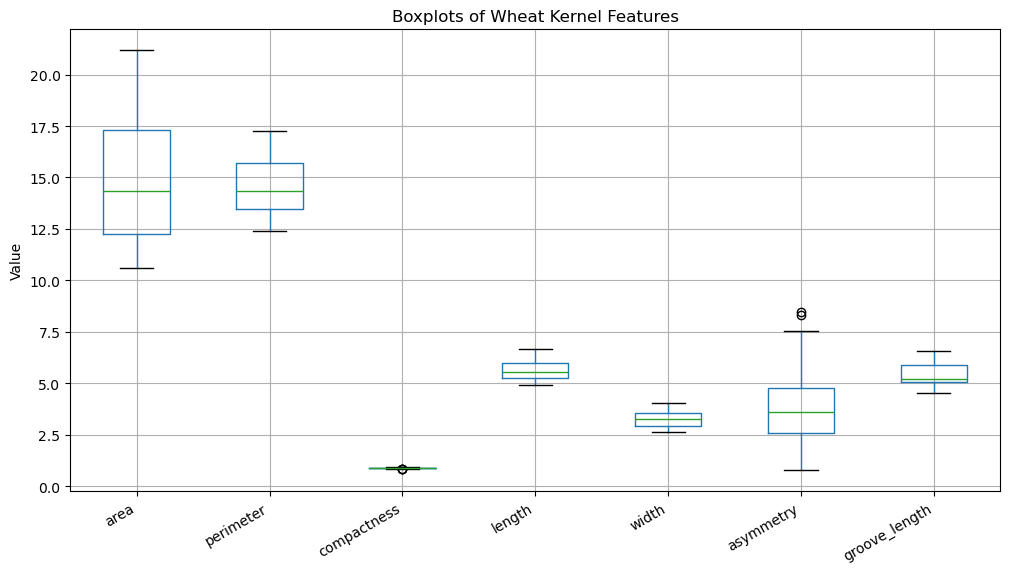

In [6]:
# ---------------------------------------------------------------------------
# Question 1.2 – Feature Distribution (Boxplots)
# Objective: Visualize each feature distribution to understand spread/outliers
# ---------------------------------------------------------------------------

print("\n" + "="*70)
print("Question 1.2 – Feature Distribution (Boxplots)")
print("="*70)

import matplotlib.pyplot as plt

# Map current columns → canonical names from the assignment
df.columns = [
    "area", "perimeter", "compactness", "length",
    "width", "asymmetry", "groove_length", "class"
]

# Replot with clean labels
feature_cols = ["area","perimeter","compactness","length","width","asymmetry","groove_length"]

plt.figure(figsize=(12, 6))
df[feature_cols].boxplot()
plt.title("Boxplots of Wheat Kernel Features")
plt.xticks(rotation=30, ha="right")
plt.ylabel("Value")
plt.show()




Question 2.0 – K-means Clustering
Homogeneity Score: 0.6734
Completeness Score: 0.6752
Adjusted Rand Index: 0.7049
Silhouette Score: 0.4221


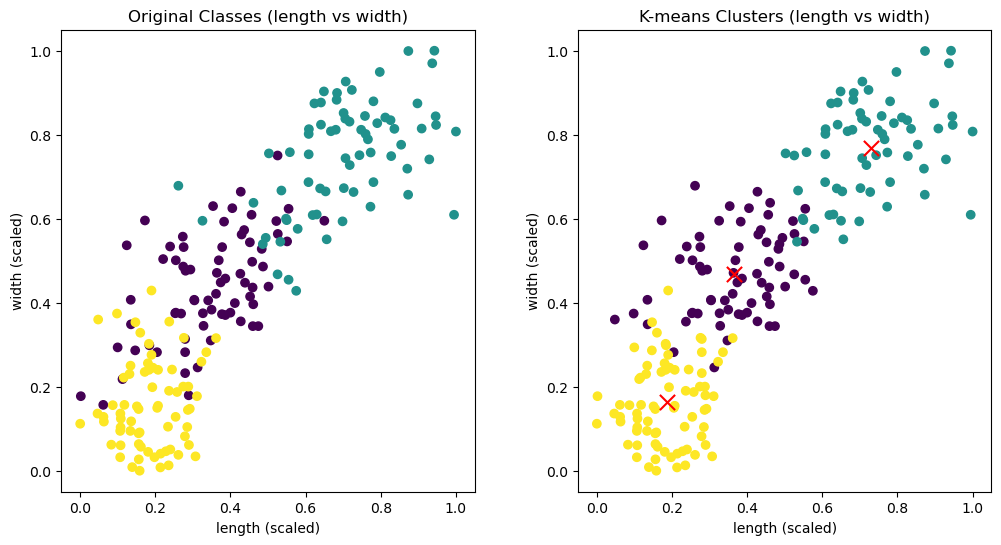

In [9]:
# ---------------------------------------------------------------------------
# Question 2 – K-means Clustering
# ---------------------------------------------------------------------------

print("\n" + "="*70)
print("Question 2 – K-means Clustering")
print("="*70)

import os
os.environ["OMP_NUM_THREADS"] = "1"  # optional: avoid Windows+MKL warning
import warnings
warnings.filterwarnings(
    "ignore",
    message=r"KMeans is known to have a memory leak on Windows with MKL.*",
    category=UserWarning,
    module="sklearn.cluster._kmeans"
)


from sklearn.cluster import KMeans
from sklearn import metrics
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

# 1) Features/labels
X = df.drop("class", axis=1).values
y = df["class"].values

# 2) Scale per lesson
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# 3) KMeans (3 clusters = 3 varieties)
kmeans = KMeans(n_clusters=3, random_state=130)
y_pred = kmeans.fit_predict(X_scaled)

# 4) Metrics (formatted)
hs  = metrics.homogeneity_score(y, y_pred)
cs  = metrics.completeness_score(y, y_pred)
ari = metrics.adjusted_rand_score(y, y_pred)
sil = metrics.silhouette_score(X_scaled, y_pred)

print(f"Homogeneity Score: {hs:.4f}")
print(f"Completeness Score: {cs:.4f}")
print(f"Adjusted Rand Index: {ari:.4f}")
print(f"Silhouette Score: {sil:.4f}")

# 5) Plot: length vs width (scaled), as in lesson’s two-feature view
centers = kmeans.cluster_centers_

plt.figure(figsize=(12, 6))
plt.subplot(121)
plt.scatter(X_scaled[:, 3], X_scaled[:, 4], c=y)
plt.title("Original Classes (length vs width)")
plt.xlabel("length (scaled)")
plt.ylabel("width (scaled)")

plt.subplot(122)
plt.scatter(X_scaled[:, 3], X_scaled[:, 4], c=y_pred)
plt.scatter(centers[:, 3], centers[:, 4], s=120, c='red', marker='x')
plt.title("K-means Clusters (length vs width)")
plt.xlabel("length (scaled)")
plt.ylabel("width (scaled)")
plt.subplots_adjust(wspace=0.25)
plt.show()



Question 3.0 – Hierarchical Clustering

Hierarchical clustering results:
Average    | Homog: 0.7017  Compl: 0.7098  ARI: 0.7247  Sil: 0.3944
Complete   | Homog: 0.6088  Compl: 0.6357  ARI: 0.5664  Sil: 0.3638
Ward       | Homog: 0.6826  Compl: 0.6975  ARI: 0.6752  Sil: 0.3810


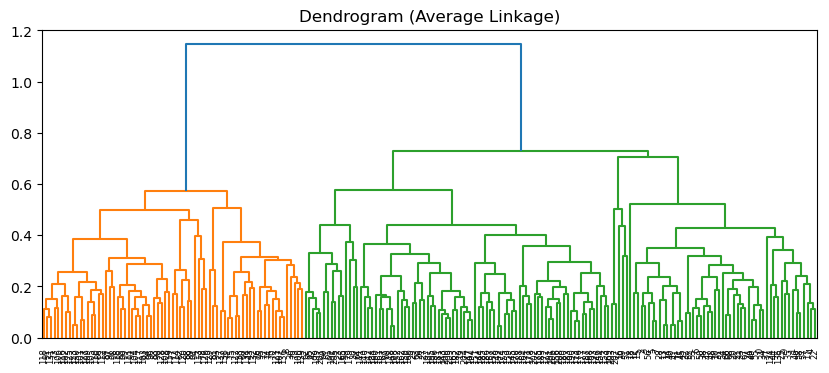

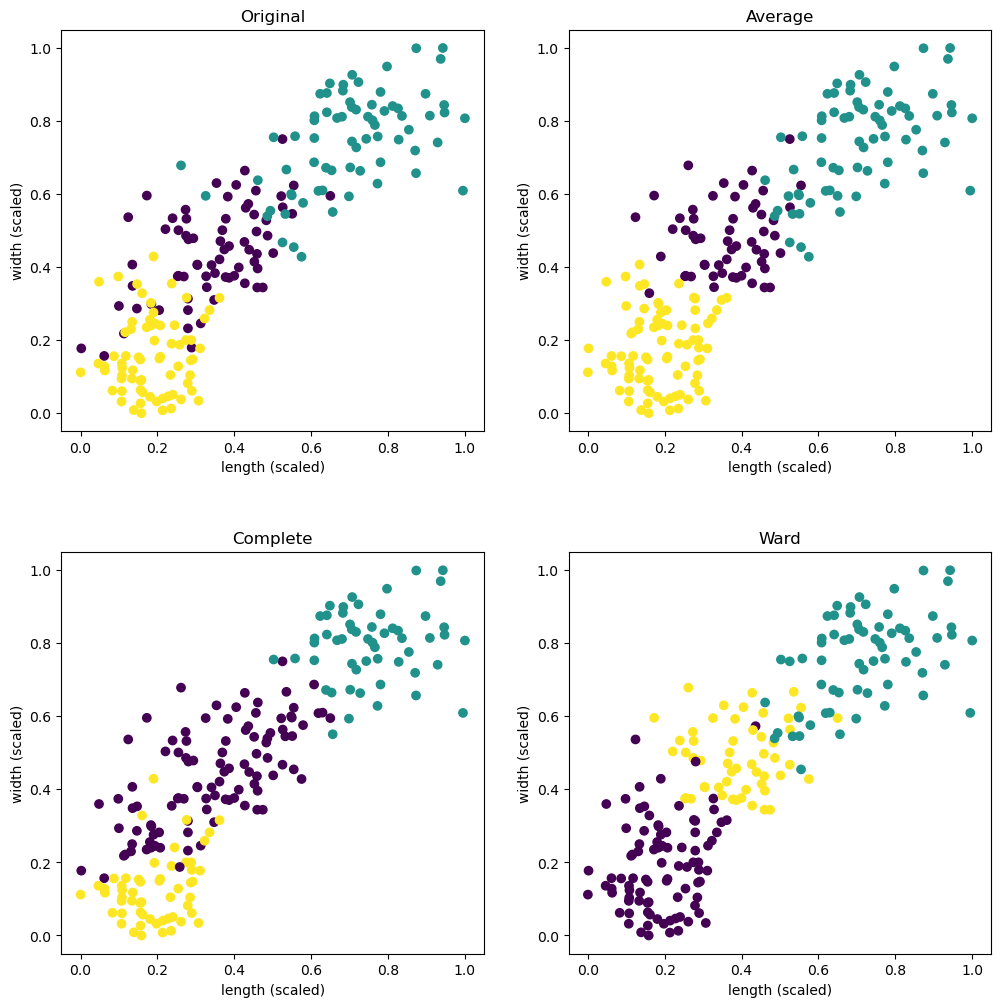

In [11]:
# ---------------------------------------------------------------------------
# Question 3 – Hierarchical Clustering (Average, Complete, Ward)
# ---------------------------------------------------------------------------

print("\n" + "="*70)
print("Question 3 – Hierarchical Clustering")
print("="*70)

from sklearn.cluster import AgglomerativeClustering
from sklearn import metrics
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

# Helper: works with both new (metric=) and old (affinity=) sklearn APIs
def agglom_predict(n_clusters, linkage_type, X, metric_name="euclidean"):
    try:
        # New API (>=1.4): uses 'metric'
        model = AgglomerativeClustering(
            n_clusters=n_clusters,
            linkage=linkage_type,
            metric=metric_name
        )
    except TypeError:
        # Legacy API: uses 'affinity'
        model = AgglomerativeClustering(
            n_clusters=n_clusters,
            linkage=linkage_type,
            affinity=metric_name
        )
    return model.fit_predict(X)

# Use the scaled features and true labels from earlier steps
# X_scaled, y assumed available from Q2

# Predictions for each linkage (lesson uses Euclidean distance)
avg_pred  = agglom_predict(3, "average",  X_scaled, "euclidean")
comp_pred = agglom_predict(3, "complete", X_scaled, "euclidean")
ward_pred = agglom_predict(3, "ward",     X_scaled, "euclidean")  # Ward requires Euclidean

# Metrics (lesson set)
def eval_and_print(name, pred):
    hs  = metrics.homogeneity_score(y, pred)
    cs  = metrics.completeness_score(y, pred)
    ari = metrics.adjusted_rand_score(y, pred)
    sil = metrics.silhouette_score(X_scaled, pred)
    print(f"{name:10s} | Homog: {hs:.4f}  Compl: {cs:.4f}  ARI: {ari:.4f}  Sil: {sil:.4f}")

print("\nHierarchical clustering results:")
eval_and_print("Average",  avg_pred)
eval_and_print("Complete", comp_pred)
eval_and_print("Ward",     ward_pred)

# Dendrogram for Average linkage (per lesson)
plt.figure(figsize=(10, 4))
Z = linkage(X_scaled, method="average")
dendrogram(Z, leaf_font_size=6)
plt.title("Dendrogram (Average Linkage)")
plt.show()

# 2×2 scatter: Original vs. three linkages (length vs width), mirroring lesson style
plt.figure(figsize=(12, 12))
methods = [("Original", y), ("Average", avg_pred),
           ("Complete", comp_pred), ("Ward", ward_pred)]
for i, (title, pred) in enumerate(methods, 1):
    plt.subplot(2, 2, i)
    plt.scatter(X_scaled[:, 3], X_scaled[:, 4], c=pred)
    plt.title(title)
    plt.xlabel("length (scaled)")
    plt.ylabel("width (scaled)")
plt.subplots_adjust(wspace=0.2, hspace=0.3)
plt.show()




Question 4.0 – DBSCAN Clustering
Initial DBSCAN Results (eps=0.2, min_samples=5)
Homogeneity Score: 0.4642
Completeness Score: 0.4592
Adjusted Rand Index: 0.3839
Silhouette Score (noise removed): 0.2034

Grid Search Results (eps, min_samples, silhouette, n_clusters):
(0.1, 5, nan, 0)
(0.1, 10, nan, 0)
(0.1, 15, nan, 0)
(0.2, 5, np.float64(0.2033812379616103), 4)
(0.2, 10, np.float64(0.5641823167439021), 3)
(0.2, 15, np.float64(0.5980599581039276), 3)
(0.3, 5, nan, 1)
(0.3, 10, nan, 1)
(0.3, 15, nan, 1)
(0.4, 5, nan, 1)
(0.4, 10, nan, 1)
(0.4, 15, nan, 1)

Best parameters (by silhouette score):
eps=0.2, min_samples=15, silhouette=0.5981, clusters=3


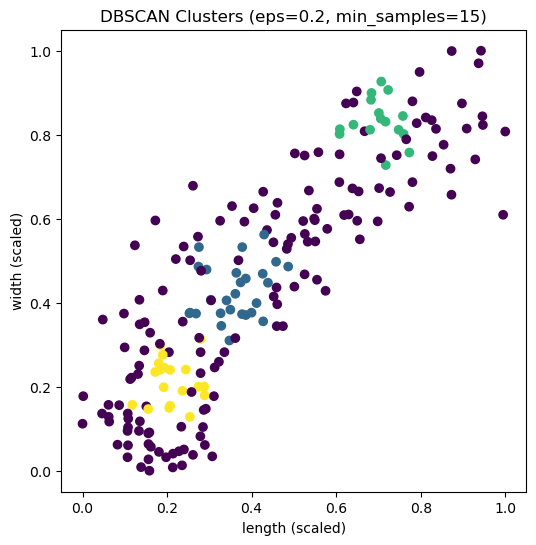

In [12]:
# ---------------------------------------------------------------------------
# Question 4 – DBSCAN Clustering
# Objective: Cluster seeds using DBSCAN and tune eps & min_samples manually.
# ---------------------------------------------------------------------------

print("\n" + "="*70)
print("Question 4 – DBSCAN Clustering")
print("="*70)

from sklearn.cluster import DBSCAN
from sklearn import metrics
import numpy as np
import matplotlib.pyplot as plt

# Initial DBSCAN model (lesson pattern uses a starting guess, then grid search)
dbscan = DBSCAN(eps=0.2, min_samples=5)
db_pred = dbscan.fit_predict(X_scaled)

# Filter out noise (-1) for silhouette (DBSCAN may assign noise points)
mask = db_pred != -1
if np.any(mask):
    sil = metrics.silhouette_score(X_scaled[mask], db_pred[mask])
else:
    sil = np.nan

# Core evaluation metrics (lesson set)
hs  = metrics.homogeneity_score(y, db_pred)
cs  = metrics.completeness_score(y, db_pred)
ari = metrics.adjusted_rand_score(y, db_pred)

print(f"Initial DBSCAN Results (eps=0.2, min_samples=5)")
print(f"Homogeneity Score: {hs:.4f}")
print(f"Completeness Score: {cs:.4f}")
print(f"Adjusted Rand Index: {ari:.4f}")
print(f"Silhouette Score (noise removed): {sil:.4f}")

# ---------------------------------------------------------------------------
# Manual grid search for eps & min_samples (as in lesson)
# ---------------------------------------------------------------------------

eps_values = [0.1, 0.2, 0.3, 0.4]
min_samples_values = [5, 10, 15]

results = []

for eps in eps_values:
    for ms in min_samples_values:
        model = DBSCAN(eps=eps, min_samples=ms)
        labels = model.fit_predict(X_scaled)

        # Count clusters (excluding noise)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

        # Compute silhouette ignoring noise
        if n_clusters > 1 and np.any(labels != -1):
            mask = labels != -1
            sil = metrics.silhouette_score(X_scaled[mask], labels[mask])
        else:
            sil = np.nan

        results.append((eps, ms, sil, n_clusters))

# Display results
print("\nGrid Search Results (eps, min_samples, silhouette, n_clusters):")
for r in results:
    print(r)

# Best result (highest silhouette)
valid = [r for r in results if not np.isnan(r[2])]
best = max(valid, key=lambda x: x[2])

print("\nBest parameters (by silhouette score):")
print(f"eps={best[0]}, min_samples={best[1]}, silhouette={best[2]:.4f}, clusters={best[3]}")
best_eps, best_ms = best[0], best[1]

# ---------------------------------------------------------------------------
# Plot clusters using best DBSCAN configuration
# ---------------------------------------------------------------------------

best_model = DBSCAN(eps=best_eps, min_samples=best_ms).fit(X_scaled)
best_pred = best_model.labels_

plt.figure(figsize=(6,6))
plt.scatter(X_scaled[:, 3], X_scaled[:, 4], c=best_pred)
plt.title(f"DBSCAN Clusters (eps={best_eps}, min_samples={best_ms})")
plt.xlabel("length (scaled)")
plt.ylabel("width (scaled)")
plt.show()
